# M5 Demand Forecasting - Notebook 1: Exploratory Data Analysis

**Goal of this notebook:** understand the Walmart M5 sales data well enough to make good modelling decisions in Notebook 2-3.

Everything here reads from the SQLite database built by `python -m src.build_database`.
Figures are saved to `reports/figures/` so you can reuse them in the README and dashboard.

**Sections:** 1) Dataset overview, 2) Data quality, 3) Sales over time, 4) Seasonality, 5) Categories and stores, 6) Intermittent demand, 7) SNAP and events, 8) Price, 9) Pareto / ABC preview, 10) Key findings

In [1]:
import sys, sqlite3
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
config.FIG_DIR.mkdir(parents=True, exist_ok=True)

db_path = config.DB_PATH
if not db_path.exists():
    raise FileNotFoundError(
        f"Database not found: {db_path}\n"
        "Build it first. In a terminal, from the project folder, run:\n"
        "    python -m src.build_database")

con = sqlite3.connect(db_path.as_uri() + "?mode=ro", uri=True)   # read-only: never creates an empty file
required = {"dim_series", "fact_sales", "fact_prices", "agg_daily_store_cat", "series_profile"}
found = {r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type = 'table'")}
if required - found:
    raise RuntimeError(
        f"The database exists but is incomplete (missing: {sorted(required - found)}).\n"
        "The build did not finish. Re-run in a terminal: python -m src.build_database")

def q(sql):
    return pd.read_sql_query(sql, con)

def save(fig, name):
    fig.savefig(config.FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

print("Database:", config.DB_PATH)

Database: D:\Project\m5-demand-forecasting\data\processed\m5.db


## 1. Dataset overview

In [2]:
overview = q("""
SELECT
  (SELECT COUNT(*) FROM dim_series)                    AS series,
  (SELECT COUNT(DISTINCT store_id) FROM dim_series)    AS stores,
  (SELECT COUNT(DISTINCT item_id) FROM dim_series)     AS items,
  (SELECT MIN(date) FROM dim_calendar)                 AS first_date,
  (SELECT MAX(date) FROM dim_calendar)                 AS last_date,
  (SELECT COUNT(*) FROM fact_sales)                    AS sales_rows,
  (SELECT COUNT(*) FROM fact_prices)                   AS price_rows
""")
overview.T.rename(columns={0: "value"})

,value
series,12196
stores,4
items,3049
first_date,2011-01-29
last_date,2016-06-19
sales_rows,23672436
price_rows,2708822


## 2. Data quality: items launch at different times

In M5 an item has **no price before it is first sold in a store**. Sales of 0 before that date are not real "zero demand", the item simply was not on the shelf. Mixing these zeros into the training data would bias every model, so from now on we only count days where a price exists ("active" days).

Series-days without a price (item not on sale yet): 21.6%
Series that launched after day 1: 63.0%
Units sold on days without a price (should be ~0): 0


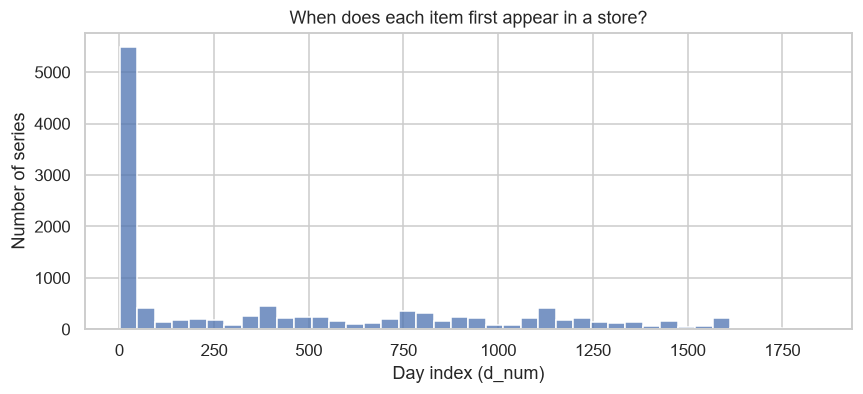

In [3]:
prof = q("""
SELECT p.*, sr.store_id, sr.item_id, i.cat_id, i.dept_id
FROM series_profile p
JOIN dim_series sr ON sr.series_id = p.series_id
JOIN dim_item i ON i.item_id = sr.item_id
""")
n_days = q("SELECT COUNT(DISTINCT d_num) AS n FROM fact_sales")["n"][0]
pct_no_price = 100 * prof["days_without_price"].sum() / (len(prof) * n_days)
launched_late = (prof["first_price_d"] > 1).mean() * 100
print(f"Series-days without a price (item not on sale yet): {pct_no_price:.1f}%")
print(f"Series that launched after day 1: {launched_late:.1f}%")
print(f"Units sold on days without a price (should be ~0): {prof['units_without_price'].sum():,}")

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.histplot(prof["first_price_d"].dropna(), bins=40, ax=ax, color="#4c72b0")
ax.set(title="When does each item first appear in a store?", xlabel="Day index (d_num)", ylabel="Number of series")
save(fig, "01_series_launch_timing"); plt.show()

## 3. Sales over time

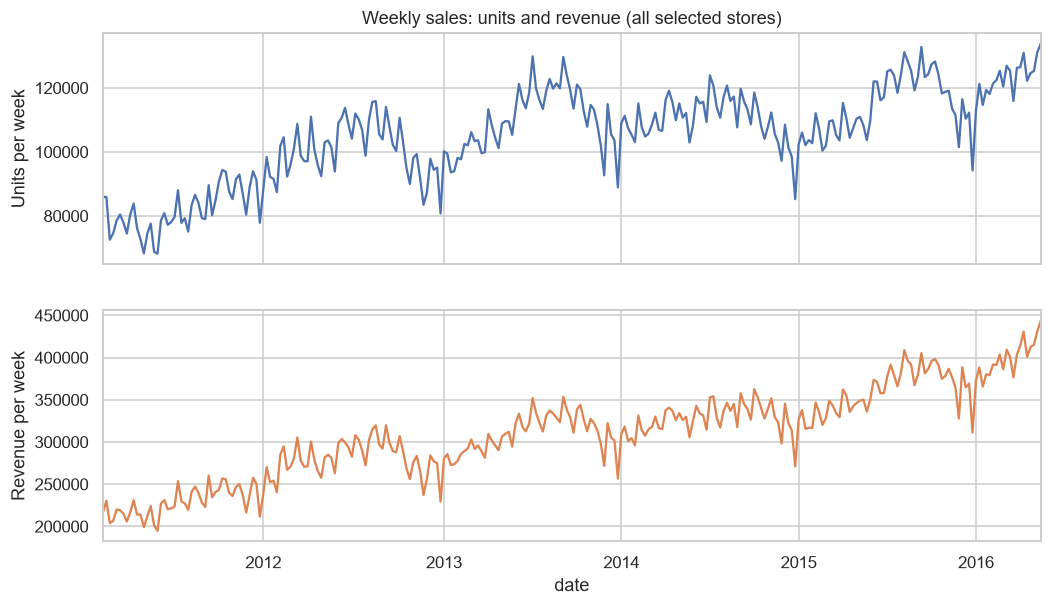

In [4]:
daily = q("""
SELECT c.date, a.store_id, a.cat_id, a.units, a.revenue
FROM agg_daily_store_cat a JOIN dim_calendar c ON c.d_num = a.d_num
""")
daily["date"] = pd.to_datetime(daily["date"])
total = daily.groupby("date")[["units", "revenue"]].sum()
weekly = total.resample("W").sum().iloc[1:-1]   # drop partial first/last week

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
weekly["units"].plot(ax=axes[0], color="#4c72b0"); axes[0].set_ylabel("Units per week")
weekly["revenue"].plot(ax=axes[1], color="#dd8452"); axes[1].set_ylabel("Revenue per week")
axes[0].set_title("Weekly sales: units and revenue (all selected stores)")
save(fig, "02_weekly_sales"); plt.show()

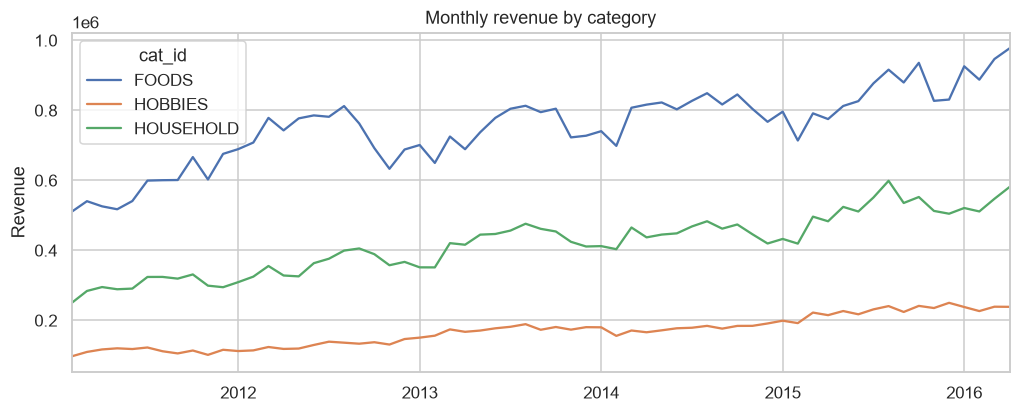

In [5]:
monthly_cat = (daily.groupby([pd.Grouper(key="date", freq="MS"), "cat_id"])["revenue"].sum().unstack())
monthly_cat = monthly_cat.iloc[1:-1]            # drop partial first/last month
fig, ax = plt.subplots(figsize=(11, 4))
monthly_cat.plot(ax=ax)
ax.set(title="Monthly revenue by category", xlabel="", ylabel="Revenue")
save(fig, "03_monthly_revenue_by_category"); plt.show()

## 4. Seasonality: day of week and month of year

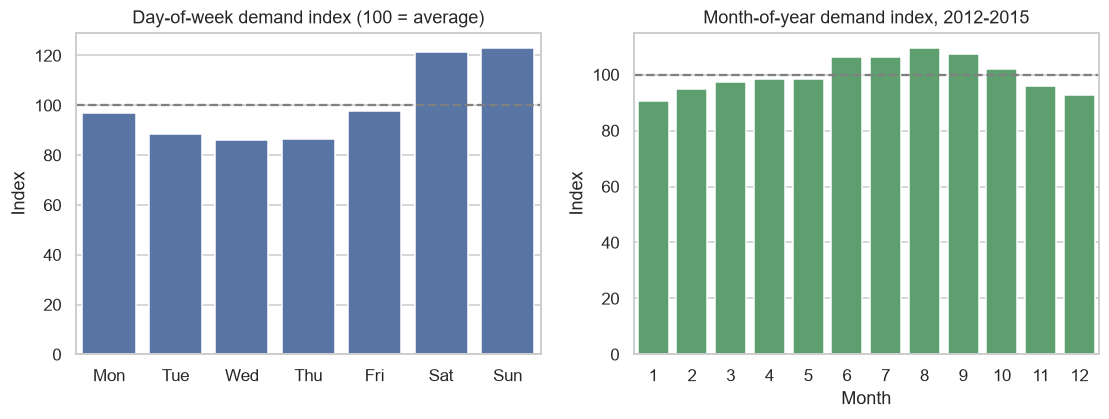

In [6]:
t = total.reset_index()
t["weekday"] = t["date"].dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = t.groupby("weekday")["units"].mean().reindex(order)
dow_index = 100 * dow / dow.mean()

full_years = t[t["date"].dt.year.between(2012, 2015)]          # complete years only
moy = full_years.groupby(full_years["date"].dt.month)["units"].mean()
moy_index = 100 * moy / moy.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.barplot(x=dow_index.index.str[:3], y=dow_index.values, ax=axes[0], color="#4c72b0")
axes[0].axhline(100, color="grey", ls="--"); axes[0].set(title="Day-of-week demand index (100 = average)", xlabel="", ylabel="Index")
sns.barplot(x=moy_index.index, y=moy_index.values, ax=axes[1], color="#55a868")
axes[1].axhline(100, color="grey", ls="--"); axes[1].set(title="Month-of-year demand index, 2012-2015", xlabel="Month", ylabel="Index")
save(fig, "04_seasonality_indices"); plt.show()

## 5. Categories and stores

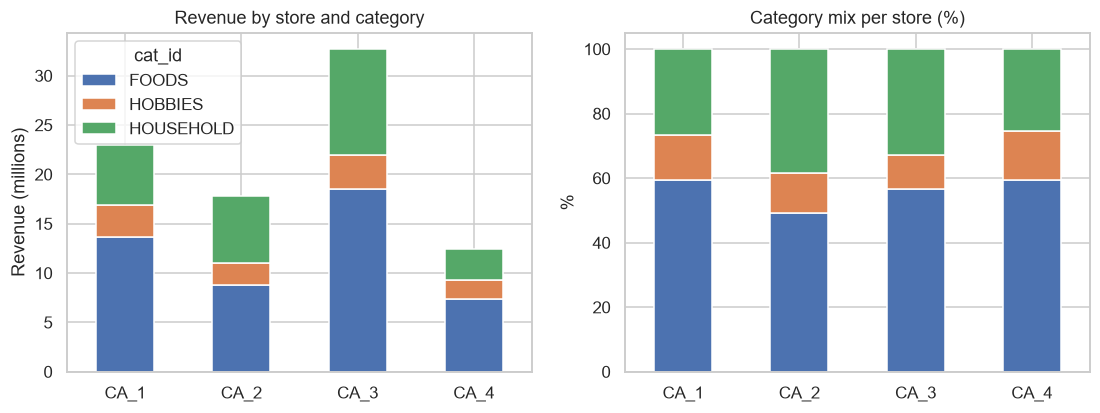

In [7]:
share = daily.groupby(["store_id", "cat_id"])["revenue"].sum().unstack()
share_pct = share.div(share.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
share.div(1e6).plot(kind="bar", stacked=True, ax=axes[0], rot=0)
axes[0].set(title="Revenue by store and category", xlabel="", ylabel="Revenue (millions)")
share_pct.plot(kind="bar", stacked=True, ax=axes[1], rot=0, legend=False)
axes[1].set(title="Category mix per store (%)", xlabel="", ylabel="%")
save(fig, "05_store_category_mix"); plt.show()

## 6. Intermittent demand

Many retail items sell only a few units per day, and some do not sell at all on most days. These "intermittent" series are hard to forecast and need special care (different error metrics, and later probably different models). Here we measure how common they are.

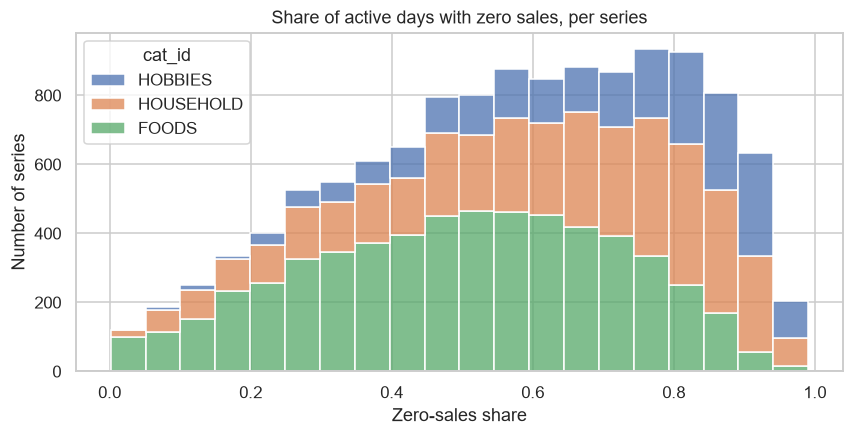

,series,median_zero_share,pct_series_over_50pct_zeros
cat_id,,,
FOODS,5748,0.51,51.53
HOBBIES,2260,0.75,80.18
HOUSEHOLD,4188,0.65,69.75


In [8]:
act = prof[prof["active_days"] > 0].copy()
act["zero_share"] = act["zero_days"] / act["active_days"]

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=act, x="zero_share", hue="cat_id", bins=20, multiple="stack", ax=ax)
ax.set(title="Share of active days with zero sales, per series", xlabel="Zero-sales share", ylabel="Number of series")
save(fig, "06_intermittency"); plt.show()

summary = act.groupby("cat_id")["zero_share"].agg(
    series="count", median_zero_share="median", pct_series_over_50pct_zeros=lambda s: 100 * (s > 0.5).mean()).round(2)
summary

## 7. SNAP days and calendar events

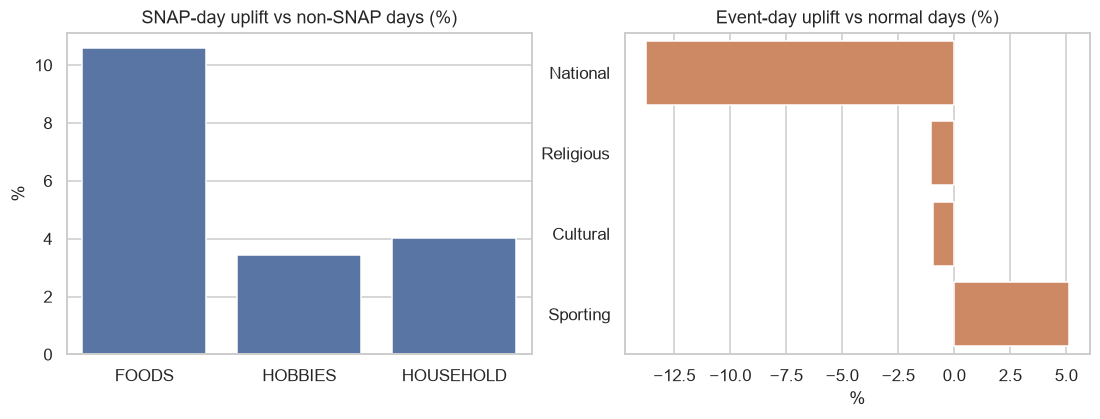

snap,non-SNAP,SNAP,uplift_pct
cat_id,,,
FOODS,2.20,2.43,10.60
HOBBIES,0.88,0.91,3.44
HOUSEHOLD,1.00,1.04,4.01


,event_type,n_days,units_per_series_day,uplift_pct
0,Cultural,37,1.56,-0.95
1,National,51,1.36,-13.76
2,No event,1783,1.58,0.00
3,Religious,54,1.56,-1.02
4,Sporting,16,1.66,5.11


In [9]:
snap = q("""
SELECT a.cat_id,
       CASE st.state_id WHEN 'CA' THEN c.snap_ca WHEN 'TX' THEN c.snap_tx ELSE c.snap_wi END AS snap,
       SUM(a.units) AS units, SUM(a.n_active) AS n_active
FROM agg_daily_store_cat a
JOIN dim_store st ON st.store_id = a.store_id
JOIN dim_calendar c ON c.d_num = a.d_num
GROUP BY a.cat_id, snap
""")
snap["units_per_series_day"] = snap["units"] / snap["n_active"]
piv = snap.pivot(index="cat_id", columns="snap", values="units_per_series_day").rename(columns={0: "non-SNAP", 1: "SNAP"})
piv["uplift_pct"] = 100 * (piv["SNAP"] / piv["non-SNAP"] - 1)

events = q("""
SELECT COALESCE(c.event_type_1, 'No event') AS event_type, COUNT(DISTINCT a.d_num) AS n_days,
       SUM(a.units) * 1.0 / SUM(a.n_active) AS units_per_series_day
FROM agg_daily_store_cat a JOIN dim_calendar c ON c.d_num = a.d_num
GROUP BY event_type
""")
base = events.loc[events["event_type"] == "No event", "units_per_series_day"].iloc[0]
events["uplift_pct"] = 100 * (events["units_per_series_day"] / base - 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.barplot(x=piv.index, y=piv["uplift_pct"], ax=axes[0], color="#4c72b0")
axes[0].set(title="SNAP-day uplift vs non-SNAP days (%)", xlabel="", ylabel="%")
ev = events[events["event_type"] != "No event"].sort_values("uplift_pct")
sns.barplot(x=ev["uplift_pct"], y=ev["event_type"], ax=axes[1], color="#dd8452")
axes[1].set(title="Event-day uplift vs normal days (%)", xlabel="%", ylabel="")
save(fig, "07_snap_and_events"); plt.show()
display(piv.round(2)); display(events.round(2))

## 8. Price

Prices change weekly. A first look at price levels per category and at how one fast-selling item reacts to its own price changes. This is a single example and **not** proof of causality, but it tells us price should be a feature in the model.

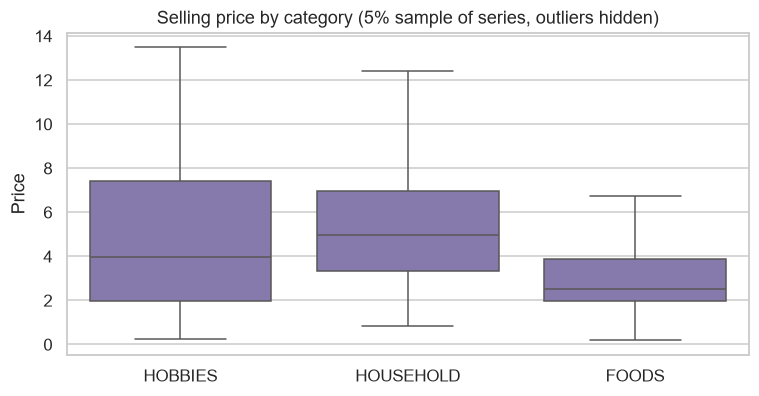

In [10]:
prices = q("""
SELECT i.cat_id, p.sell_price
FROM fact_prices p
JOIN dim_series sr ON sr.series_id = p.series_id
JOIN dim_item i ON i.item_id = sr.item_id
WHERE p.series_id % 20 = 0
""")
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=prices, x="cat_id", y="sell_price", ax=ax, color="#8172b3", showfliers=False)
ax.set(title="Selling price by category (5% sample of series, outliers hidden)", xlabel="", ylabel="Price")
save(fig, "08_price_by_category"); plt.show()

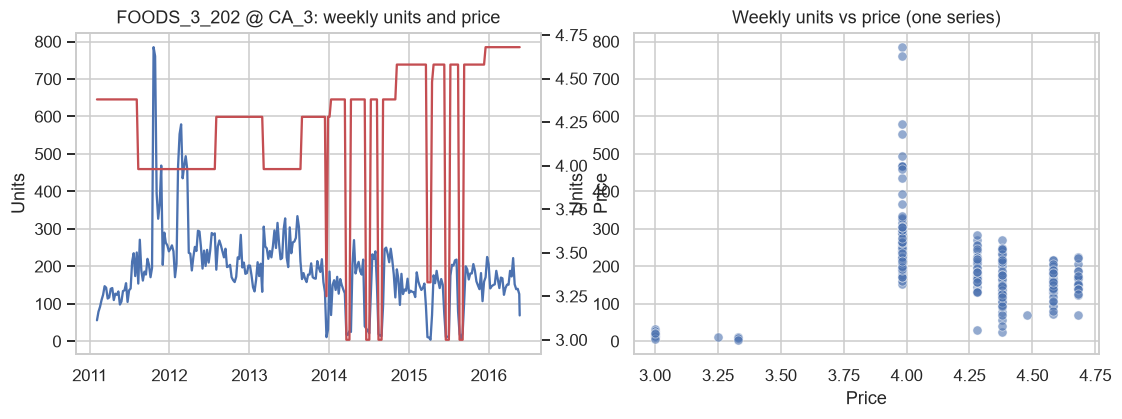

In [11]:
top = prof.sort_values("total_units", ascending=False).head(50)["series_id"].tolist()
ids = ",".join(map(str, top))
n_prices = q(f"SELECT series_id, COUNT(DISTINCT sell_price) AS n FROM fact_prices WHERE series_id IN ({ids}) GROUP BY series_id")
sid = int(n_prices.sort_values("n", ascending=False).iloc[0]["series_id"])
info = q(f"SELECT sr.store_id, sr.item_id FROM dim_series sr WHERE sr.series_id = {sid}").iloc[0]

wk = q(f"""
SELECT c.wm_yr_wk, MAX(c.date) AS date, SUM(s.sales) AS units, p.sell_price
FROM fact_sales s
JOIN dim_calendar c ON c.d_num = s.d_num
JOIN fact_prices p ON p.series_id = s.series_id AND p.wm_yr_wk = c.wm_yr_wk
WHERE s.series_id = {sid}
GROUP BY c.wm_yr_wk, p.sell_price ORDER BY c.wm_yr_wk
""")
wk["date"] = pd.to_datetime(wk["date"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(wk["date"], wk["units"], color="#4c72b0", label="Units")
ax2 = axes[0].twinx(); ax2.plot(wk["date"], wk["sell_price"], color="#c44e52", label="Price"); ax2.grid(False)
axes[0].set(title=f"{info.item_id} @ {info.store_id}: weekly units and price", ylabel="Units"); ax2.set_ylabel("Price")
sns.scatterplot(data=wk, x="sell_price", y="units", ax=axes[1], alpha=0.6)
axes[1].set(title="Weekly units vs price (one series)", xlabel="Price", ylabel="Units")
save(fig, "09_price_vs_demand_example"); plt.show()

## 9. Pareto / ABC preview

Few items usually generate most of the revenue. Classifying items into **A** (first 80% of revenue), **B** (next 15%) and **C** (last 5%) lets us focus effort and inventory policy where it matters. In week 2 we will combine this with demand variability (XYZ).

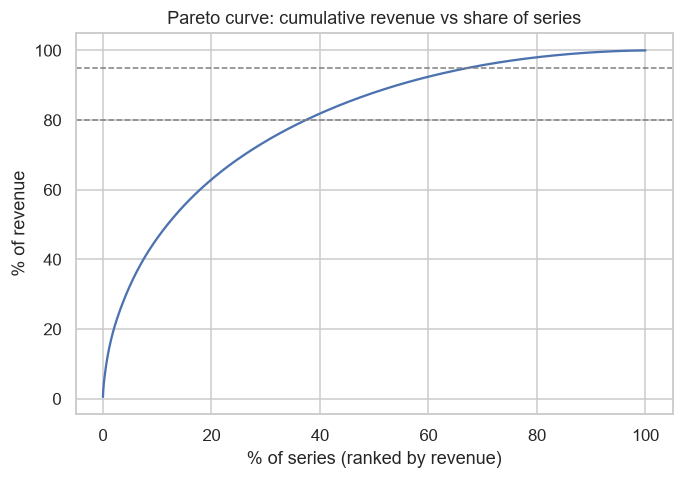

,n_series,revenue,pct_series,pct_revenue
abc,,,,
A,4557,68769008.94,37.4,80.0
B,3655,12899930.92,30.0,15.0
C,3984,4298419.17,32.7,5.0


In [12]:
p = prof.sort_values("total_revenue", ascending=False).reset_index(drop=True)
p["cum_rev_share"] = p["total_revenue"].cumsum() / p["total_revenue"].sum()
p["cum_item_share"] = (np.arange(len(p)) + 1) / len(p)
p["abc"] = np.where(p["cum_rev_share"] <= 0.80, "A", np.where(p["cum_rev_share"] <= 0.95, "B", "C"))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(p["cum_item_share"] * 100, p["cum_rev_share"] * 100, color="#4c72b0")
ax.axhline(80, color="grey", ls="--", lw=1); ax.axhline(95, color="grey", ls="--", lw=1)
ax.set(title="Pareto curve: cumulative revenue vs share of series", xlabel="% of series (ranked by revenue)", ylabel="% of revenue")
save(fig, "10_pareto_curve"); plt.show()

p.groupby("abc").agg(n_series=("series_id", "count"), revenue=("total_revenue", "sum")).assign(
    pct_series=lambda d: (100 * d["n_series"] / d["n_series"].sum()).round(1),
    pct_revenue=lambda d: (100 * d["revenue"] / d["revenue"].sum()).round(1))

## 10. Key findings (fill in after running on the real M5 data)

Write 5-8 short bullets, each with a number from your own results. Examples of what to look for:

- **Scale and structure:** how many series, how many days, what share of series-days is "not on sale yet"?
- **Seasonality:** which weekday is strongest and by how much? Is there a clear yearly pattern?
- **Mix:** which category drives revenue? Does the mix differ between stores?
- **Intermittency:** what share of series have more than 50% zero days? Which category is worst?
- **Calendar effects:** is the SNAP uplift visible, and for which category? Which event type matters most?
- **Price:** do prices change often? Does the example series react to price?
- **Concentration:** what % of series make 80% of revenue?
- **Implications for modelling:** e.g. drop pre-launch zeros, use calendar and price features, treat intermittent series separately.

*(Replace this cell with your own findings.)*

In [ ]:
con.close()